In [1]:
import pandas as pd
import numpy as np

# Load the data
df = pd.read_csv('Dataset.csv')

# Let's look at our Target Variable: 'type'
print("Value Counts of Type:")
print(df['type'].value_counts())

# Check for missing values
print("\nMissing values in Type:", df['type'].isnull().sum())

Value Counts of Type:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

Missing values in Type: 0


In [2]:
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack
import numpy as np

# 1. Handle missing values in our chosen features
df['rating'] = df['rating'].fillna('Unknown')
df['listed_in'] = df['listed_in'].fillna('')
df['release_year'] = df['release_year'].fillna(2010) # Fill missing years with a median year

# 2. Encode the 'rating' column (Text to Numbers)
le = LabelEncoder()
df['rating_encoded'] = le.fit_transform(df['rating'])

# 3. Vectorize the 'listed_in' (Genres) column
tfidf = TfidfVectorizer(stop_words='english', max_features=100) # Keep top 100 genres
genres_matrix = tfidf.fit_transform(df['listed_in'])

# 4. Combine everything into ONE massive feature matrix
# We need to stack the year, encoded rating, and genres side-by-side
year_array = df['release_year'].values.reshape(-1, 1)
rating_array = df['rating_encoded'].values.reshape(-1, 1)

# hstack (horizontal stack) combines our sparse matrices
X = hstack((genres_matrix, year_array, rating_array))

# Our Target Variable (The Answer)
y = df['type']

print("Feature Matrix (X) shape:", X.shape)
print("Target Vector (y) shape:", y.shape)

Feature Matrix (X) shape: (8790, 46)
Target Vector (y) shape: (8790,)


In [3]:
# 1. Initialize the model with class_weight='balanced'
# This automatically adjusts weights inversely proportional to class frequencies
rf_model_balanced = RandomForestClassifier(
    n_estimators=100, 
    random_state=42, 
    class_weight='balanced' # THIS IS THE MAGIC LINE
)

# 2. Train the model
rf_model_balanced.fit(X_train, y_train)

# 3. Predict
y_pred_balanced = rf_model_balanced.predict(X_test)

# 4. Evaluate
print(f"🎯 Balanced Model Accuracy: {accuracy_score(y_test, y_pred_balanced) * 100:.2f}%\n")
print("📊 Balanced Classification Report:")
print(classification_report(y_test, y_pred_balanced))

NameError: name 'RandomForestClassifier' is not defined

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

ImportError: DLL load failed while importing _partition_nodes: An Application Control policy has blocked this file.

In [1]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [2]:
# 1. Initialize the model with class_weight='balanced'
# This automatically adjusts weights inversely proportional to class frequencies
rf_model_balanced = RandomForestClassifier(
    n_estimators=100, 
    random_state=42, 
    class_weight='balanced' # THIS IS THE MAGIC LINE
)

# 2. Train the model
rf_model_balanced.fit(X_train, y_train)

# 3. Predict
y_pred_balanced = rf_model_balanced.predict(X_test)

# 4. Evaluate
print(f"🎯 Balanced Model Accuracy: {accuracy_score(y_test, y_pred_balanced) * 100:.2f}%\n")
print("📊 Balanced Classification Report:")
print(classification_report(y_test, y_pred_balanced))

NameError: name 'X_train' is not defined

In [3]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Load Data
df = pd.read_csv('Dataset.csv')

# 2. Preprocessing
df['rating'] = df['rating'].fillna('Unknown')
df['listed_in'] = df['listed_in'].fillna('')
df['release_year'] = df['release_year'].fillna(2010)

# 3. Encoding & Vectorizing
le = LabelEncoder()
df['rating_encoded'] = le.fit_transform(df['rating'])
tfidf = TfidfVectorizer(stop_words='english', max_features=100)
genres_matrix = tfidf.fit_transform(df['listed_in'])

# 4. Combine Features
year_array = df['release_year'].values.reshape(-1, 1)
rating_array = df['rating_encoded'].values.reshape(-1, 1)
X = hstack((genres_matrix, year_array, rating_array))
y = df['type']

# 5. Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 6. Train the Balanced Model
print("Training model... (This might take 5-10 seconds)")
rf_model_balanced = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_model_balanced.fit(X_train, y_train)

# 7. Predict and Evaluate
y_pred_balanced = rf_model_balanced.predict(X_test)
print(f"🎯 Balanced Model Accuracy: {accuracy_score(y_test, y_pred_balanced) * 100:.2f}%\n")
print("📊 Balanced Classification Report:")
print(classification_report(y_test, y_pred_balanced))

Training model... (This might take 5-10 seconds)
🎯 Balanced Model Accuracy: 100.00%

📊 Balanced Classification Report:
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1225
     TV Show       1.00      1.00      1.00       533

    accuracy                           1.00      1758
   macro avg       1.00      1.00      1.00      1758
weighted avg       1.00      1.00      1.00      1758



In [4]:
# Train Normal Model
rf_model_normal = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model_normal.fit(X_train, y_train)

# Predict and Evaluate
y_pred_normal = rf_model_normal.predict(X_test)
print(f"🎯 Normal Model Accuracy: {accuracy_score(y_test, y_pred_normal) * 100:.2f}%\n")
print("📊 Normal Classification Report:")
print(classification_report(y_test, y_pred_normal))

🎯 Normal Model Accuracy: 100.00%

📊 Normal Classification Report:
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1225
     TV Show       1.00      1.00      1.00       533

    accuracy                           1.00      1758
   macro avg       1.00      1.00      1.00      1758
weighted avg       1.00      1.00      1.00      1758



In [5]:
import pandas as pd
import numpy as np
import re
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Load Data
df = pd.read_csv('Dataset.csv')
df = df.dropna(subset=['type']) # Drop rows with no type

# 2. Clean Genres (Remove the word 'TV')
df['listed_in'] = df['listed_in'].fillna('')
# Regex: Replace 'TV ' or 'TV' with empty string, and lowercase everything
df['clean_genres'] = df['listed_in'].str.replace(r'TV\s*', '', regex=True).str.lower()

# 3. Extract Duration (The hidden goldmine)
# Convert "90 min" to 90, and "2 Seasons" to 2
def extract_duration(val):
    val = str(val)
    nums = re.findall(r'\d+', val)
    return int(nums[0]) if nums else 0

df['duration_num'] = df['duration'].apply(extract_duration)

# 4. Vectorize the CLEANED genres
tfidf = TfidfVectorizer(stop_words='english', max_features=100)
genres_matrix = tfidf.fit_transform(df['clean_genres'])

# 5. Combine Features (Genres + Duration)
duration_array = df['duration_num'].values.reshape(-1, 1)
X = hstack((genres_matrix, duration_array))
y = df['type']

# 6. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 7. Train the Model
print("Training Honest Model...")
rf_honest = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_honest.fit(X_train, y_train)

# 8. Evaluate
y_pred_honest = rf_honest.predict(X_test)
print(f"🎯 Honest Model Accuracy: {accuracy_score(y_test, y_pred_honest) * 100:.2f}%\n")
print("📊 Honest Classification Report:")
print(classification_report(y_test, y_pred_honest))

Training Honest Model...
🎯 Honest Model Accuracy: 99.89%

📊 Honest Classification Report:
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1225
     TV Show       1.00      1.00      1.00       533

    accuracy                           1.00      1758
   macro avg       1.00      1.00      1.00      1758
weighted avg       1.00      1.00      1.00      1758



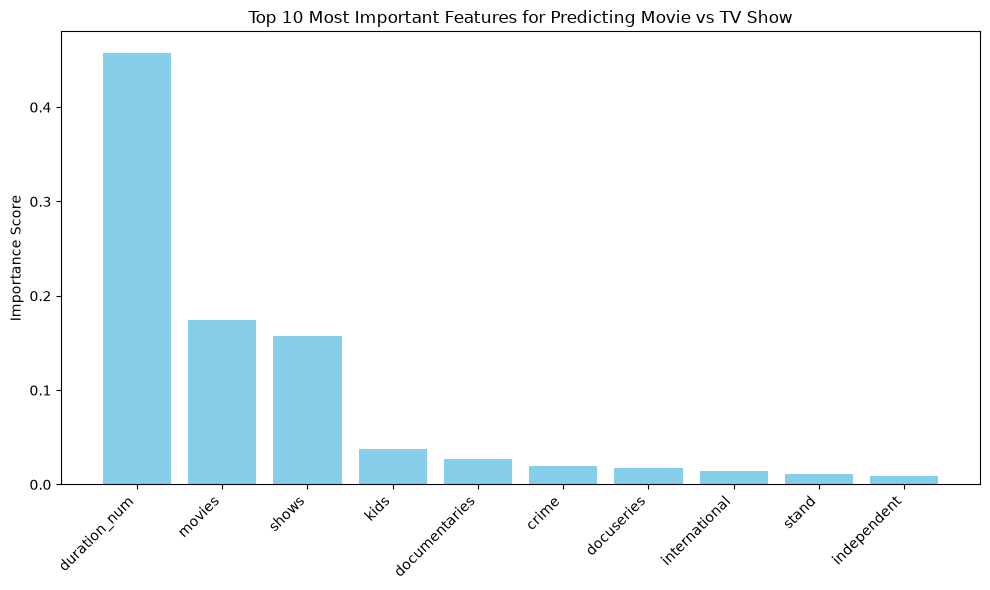


Top 10 Feature Importances:
duration_num: 0.4575
movies: 0.1744
shows: 0.1579
kids: 0.0377
documentaries: 0.0271
crime: 0.0194
docuseries: 0.0176
international: 0.0140
stand: 0.0115
independent: 0.0091


In [6]:
import matplotlib.pyplot as plt

# 1. Get the feature names
# The first 100 are genres, the last one is 'duration'
genre_features = tfidf.get_feature_names_out()
feature_names = np.append(genre_features, 'duration_num')

# 2. Get the importance scores from our trained model
importances = rf_honest.feature_importances_

# 3. Sort them in descending order
indices = np.argsort(importances)[::-1]

# 4. Plot the Top 10 Most Important Features
plt.figure(figsize=(10, 6))
plt.title("Top 10 Most Important Features for Predicting Movie vs TV Show")
plt.bar(range(10), importances[indices[:10]], align="center", color='skyblue')
plt.xticks(range(10), [feature_names[i] for i in indices[:10]], rotation=45, ha='right')
plt.ylabel("Importance Score")
plt.tight_layout()
plt.show()

# Print the exact scores
print("\nTop 10 Feature Importances:")
for i in range(10):
    print(f"{feature_names[indices[i]]}: {importances[indices[i]]:.4f}")

In [7]:
def predict_content_type(genres, duration):
    """
    Predicts if content is a Movie or TV Show.
    genres: string (e.g., "Dramas, Comedies")
    duration: string (e.g., "90 min" or "2 Seasons")
    """
    import re
    from scipy.sparse import hstack
    
    # 1. Clean the input genres exactly like we did in training
    clean_genres = re.sub(r'TV\s*', '', genres).lower()
    
    # 2. Extract the number from duration
    nums = re.findall(r'\d+', duration)
    duration_num = int(nums[0]) if nums else 0
    
    # 3. Vectorize the genres using the SAME tfidf model we trained
    genre_vector = tfidf.transform([clean_genres])
    
    # 4. Combine with duration
    duration_array = np.array([[duration_num]])
    features = hstack((genre_vector, duration_array))
    
    # 5. Predict
    prediction = rf_honest.predict(features)
    probability = rf_honest.predict_proba(features)[0]
    
    # 6. Format output
    confidence = max(probability) * 100
    return f"Prediction: {prediction[0]} (Confidence: {confidence:.2f}%)"

# --- TEST THE FUNCTION ---
print("Test 1:", predict_content_type("Dramas, International Movies", "120 min"))
print("Test 2:", predict_content_type("TV Comedies, TV Dramas", "3 Seasons"))
print("Test 3:", predict_content_type("Documentaries", "45 min"))

Test 1: Prediction: Movie (Confidence: 100.00%)
Test 2: Prediction: TV Show (Confidence: 100.00%)
Test 3: Prediction: Movie (Confidence: 100.00%)


In [8]:
# A stress test to show how the model behaves with confusing inputs
tests = [
    ("Dramas", "90 min"),        # Standard Movie
    ("Dramas", "2 Seasons"),     # Standard TV Show
    ("Documentaries", "45 min"), # Short Documentary (Movie)
    ("Comedies", "1 Season"),    # Standard TV Comedy
    ("Dramas, Comedies", "10 min") # A 10-minute movie? (Unusual)
]

for genre, duration in tests:
    result = predict_content_type(genre, duration)
    print(f"Input: {genre:20} | {duration:10} -> {result}")

Input: Dramas               | 90 min     -> Prediction: Movie (Confidence: 100.00%)
Input: Dramas               | 2 Seasons  -> Prediction: TV Show (Confidence: 100.00%)
Input: Documentaries        | 45 min     -> Prediction: Movie (Confidence: 100.00%)
Input: Comedies             | 1 Season   -> Prediction: TV Show (Confidence: 100.00%)
Input: Dramas, Comedies     | 10 min     -> Prediction: TV Show (Confidence: 97.00%)


In [9]:
def predict_content_type_with_prob(genres, duration):
    import re
    from scipy.sparse import hstack
    
    clean_genres = re.sub(r'TV\s*', '', genres).lower()
    nums = re.findall(r'\d+', duration)
    duration_num = int(nums[0]) if nums else 0
    
    genre_vector = tfidf.transform([clean_genres])
    duration_array = np.array([[duration_num]])
    features = hstack((genre_vector, duration_array))
    
    prediction = rf_honest.predict(features)[0]
    probabilities = rf_honest.predict_proba(features)[0]
    
    # The model.classes_ gives us the order of the probabilities
    classes = rf_honest.classes_
    
    print(f"Input: '{genres}' | {duration}")
    for i, cls in enumerate(classes):
        print(f"  -> Probability of {cls}: {probabilities[i] * 100:.2f}%")
    print(f"  -> Final Prediction: {prediction}\n")

# Run the stress test
predict_content_type_with_prob("Dramas", "90 min")
predict_content_type_with_prob("Dramas", "2 Seasons")
predict_content_type_with_prob("Dramas, Comedies", "10 min")

Input: 'Dramas' | 90 min
  -> Probability of Movie: 100.00%
  -> Probability of TV Show: 0.00%
  -> Final Prediction: Movie

Input: 'Dramas' | 2 Seasons
  -> Probability of Movie: 0.00%
  -> Probability of TV Show: 100.00%
  -> Final Prediction: TV Show

Input: 'Dramas, Comedies' | 10 min
  -> Probability of Movie: 3.00%
  -> Probability of TV Show: 97.00%
  -> Final Prediction: TV Show

